# M4 视觉跟踪：合成序列验证
当前为卡尔曼滤波 + 两阶段 IoU + 贪心关联的简化实现，未实现完整 BoT-SORT 的 ReID/GMC。下面所有轨迹均为合成测试，不代表无人机实测。

In [1]:
from pathlib import Path
import os, sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'code').is_dir() and (p/'catkin_ws').is_dir()), None)
assert ROOT is not None, '请从项目根目录或 code/ 打开笔记本'
for p in [ROOT/'catkin_ws/src/uav_tracking/scripts', ROOT/'code', ROOT/'lib/m4']:
    sys.path.insert(0, str(p))
os.environ.setdefault('UAV_STAGE', 'dev')
# Ubuntu .pth 文件可能提前注册系统 mpl_toolkits；统一到隔离版。
import mpl_toolkits
isolated_toolkits = str(ROOT/'lib/m4/mpl_toolkits')
mpl_toolkits.__path__ = [isolated_toolkits] + [p for p in mpl_toolkits.__path__ if p != isolated_toolkits]
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 110})
ASSETS = ROOT/'test/M4_现场验证/实时演示/assets'
print('项目:', ROOT)
print('NumPy:', np.__version__, np.__file__)


项目: /home/demo/projects/m4-release-zxzf82xb
NumPy: 1.21.6 /home/demo/projects/m4-release-zxzf82xb/lib/m4/numpy/__init__.py


## 1. ID 稳定、低分关联与丢失恢复

In [2]:
from visual_tracker import BotSortTracker
from datatypes import DetectedTarget
def det(x=100., y=100., confidence=.9, class_id=0, w=60., h=45.):
    return DetectedTarget(class_id=class_id,confidence=confidence,bbox=(x,y,w,h))
tracker = BotSortTracker(frame_size=(640,480),track_buffer=3)
first = tracker.track([det()])[0].id
assert tracker.track([det(x=102.,confidence=.3)])[0].id == first
assert tracker.track([]) == []
assert tracker.track([det(x=104.)])[0].id == first
other_class = tracker.track([det(x=104.,class_id=1)])[0].id
assert other_class != first
print('低分关联、短时恢复、类别隔离: PASS')


低分关联、短时恢复、类别隔离: PASS


## 2. 合成运动、目标尺寸与面积占比
track_buffer 按处理帧计数，不是秒。2% 是面积门槛示例；没有相机标定和目标尺寸模型，不能由此换算成 100 米。

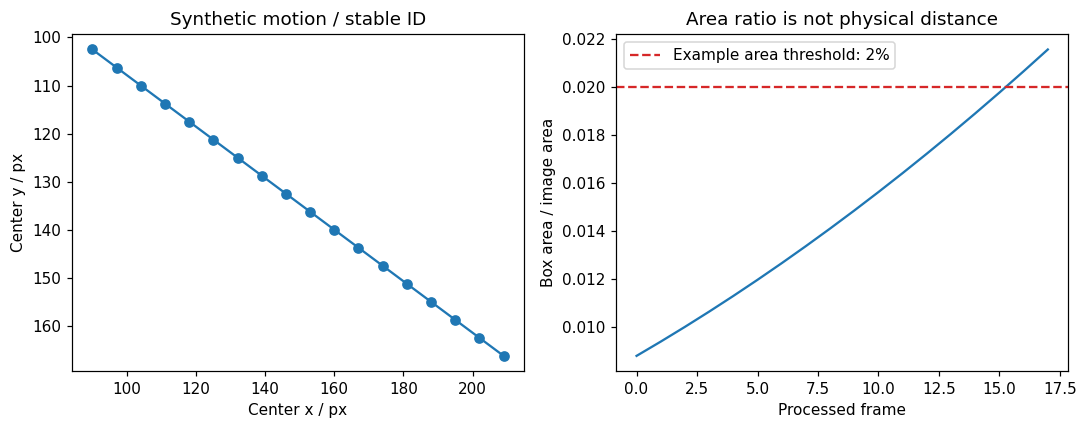

In [3]:
tracker = BotSortTracker(frame_size=(640,480))
rows = []
for frame in range(18):
    tracks = tracker.track([det(x=60.+frame*6,y=80.+frame*3,w=60.+frame*2,h=45.+frame*1.5)])
    target = tracks[0]
    x,y,w,h = target.bbox
    rows.append((frame,target.id,x+w/2,y+h/2,target.area_ratio))
rows = np.array(rows)
assert len(set(rows[:,1])) == 1
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(rows[:,2],rows[:,3],'o-',color='#1f77b4')
axes[0].invert_yaxis(); axes[0].set(xlabel='Center x / px',ylabel='Center y / px',title='Synthetic motion / stable ID')
axes[1].plot(rows[:,0],rows[:,4],color='#1f77b4')
axes[1].axhline(.02,color='#d62728',linestyle='--',label='Example area threshold: 2%')
axes[1].set(xlabel='Processed frame',ylabel='Box area / image area',title='Area ratio is not physical distance')
axes[1].legend(); plt.tight_layout(); plt.show()


## 3. 超过缓冲后创建新 ID

In [4]:
tracker = BotSortTracker(track_buffer=2)
first = tracker.track([det()])[0].id
for _ in range(3): assert tracker.track([]) == []
second = tracker.track([det()])[0].id
assert second != first
print('旧 ID:',first,'重新出现后的 ID:',second)


旧 ID: 1 重新出现后的 ID: 2
